##### Import Libraries

In [32]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import warnings

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_validate
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, classification_report,
                             ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay)
from sklearn.exceptions import UndefinedMetricWarning
from sklearn.metrics import precision_recall_curve, confusion_matrix
from sklearn.calibration import CalibrationDisplay
from sklearn.model_selection import learning_curve
import seaborn as sns


warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=UndefinedMetricWarning)
warnings.filterwarnings('ignore', category=UserWarning)

RANDOM_STATE = 42

##### Load the data

In [33]:
X_train = pd.read_csv('Data/X_train.csv')
X_test  = pd.read_csv('Data/X_test.csv')
y_train = pd.read_csv('Data/y_train.csv').squeeze('columns')
y_test  = pd.read_csv('Data/y_test.csv').squeeze('columns')

print('X_train:', X_train.shape, '| X_test:', X_test.shape)
print('\nClass distribution (train):')
print(y_train.value_counts(normalize=True).round(3))

X_train: (5634, 22) | X_test: (1409, 22)

Class distribution (train):
Churn
0    0.735
1    0.265
Name: proportion, dtype: float64


##### Baseline model (default settings, 5-fold CV)

In [34]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']

baseline_lr = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
])

baseline_cv = cross_validate(baseline_lr, X_train, y_train, cv=cv, scoring=scoring)

baseline_cv_df = pd.DataFrame({m: [baseline_cv[f'test_{m}'].mean(), baseline_cv[f'test_{m}'].std()]
                               for m in scoring}, index=['Mean', 'Std'])

print('Baseline Logistic Regression - 5-fold CV results')
display(baseline_cv_df.round(4))

Baseline Logistic Regression - 5-fold CV results


,accuracy,precision,recall,f1,roc_auc
Mean,0.8065,0.6661,0.5445,0.5986,0.8490
Std,0.0117,0.0293,0.0350,0.0274,0.0125


##### Hyperparameter tuning (GridSearchCV)

In [43]:
lr_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(max_iter=5000, random_state=RANDOM_STATE))
])

C_values = [0.001, 0.01, 0.1, 1, 10, 100]

# Separate grids because each solver supports different penalties
param_grid = [
    {'model__solver': ['lbfgs'], 'model__penalty': ['l2'],
     'model__C': C_values, 'model__class_weight': [None, 'balanced']},
    {'model__solver': ['liblinear'], 'model__penalty': ['l1', 'l2'],
     'model__C': C_values, 'model__class_weight': [None, 'balanced']},
    {'model__solver': ['saga'], 'model__penalty': ['elasticnet'], 'model__l1_ratio': [0.2, 0.5, 0.8],
     'model__C': C_values, 'model__class_weight': [None, 'balanced']},
]

grid_lr = GridSearchCV(lr_pipeline, param_grid, scoring=scoring, refit='f1',
                       cv=cv, n_jobs=-1, return_train_score=True)
grid_lr.fit(X_train, y_train)

print('Best parameters:', grid_lr.best_params_)
print('Best CV F1-score:', round(grid_lr.best_score_, 4))

Best parameters: {'model__C': 0.01, 'model__class_weight': 'balanced', 'model__penalty': 'l2', 'model__solver': 'lbfgs'}
Best CV F1-score: 0.6348


In [36]:
cv_results = pd.DataFrame(grid_lr.cv_results_)
cols = ['params', 'mean_test_f1', 'std_test_f1', 'mean_test_recall',
        'mean_test_precision', 'mean_test_roc_auc', 'mean_train_f1', 'rank_test_f1']
top10 = cv_results[cols].sort_values('rank_test_f1').head(10)
pd.set_option('display.max_colwidth', None)
display(top10.round(4))

,params,mean_test_f1,std_test_f1,mean_test_recall,mean_test_precision,mean_test_roc_auc,mean_train_f1,rank_test_f1
3,"{'model__C': 0.01, 'model__class_weight': 'balanced', 'model__penalty': 'l2', 'model__solver': 'lbfgs'}",0.6348,0.0204,0.8000,0.5264,0.8491,0.6404,1
1,"{'model__C': 0.001, 'model__class_weight': 'balanced', 'model__penalty': 'l2', 'model__solver': 'lbfgs'}",0.6336,0.0156,0.7953,0.5267,0.8449,0.6339,2
45,"{'model__C': 0.01, 'model__class_weight': 'balanced', 'model__l1_ratio': 0.2, 'model__penalty': 'elasticnet', 'model__solver': 'saga'}",0.6330,0.0206,0.8020,0.5230,0.8497,0.6376,3
22,"{'model__C': 0.1, 'model__class_weight': 'balanced', 'model__penalty': 'l1', 'model__solver': 'liblinear'}",0.6325,0.0196,0.8060,0.5207,0.8498,0.6376,4
53,"{'model__C': 0.1, 'model__class_weight': 'balanced', 'model__l1_ratio': 0.8, 'model__penalty': 'elasticnet', 'model__solver': 'saga'}",0.6325,0.0199,0.8000,0.5232,0.8498,0.6377,5
46,"{'model__C': 0.01, 'model__class_weight': 'balanced', 'model__l1_ratio': 0.5, 'model__penalty': 'elasticnet', 'model__solver': 'saga'}",0.6319,0.0221,0.8060,0.5199,0.8492,0.6372,6
52,"{'model__C': 0.1, 'model__class_weight': 'balanced', 'model__l1_ratio': 0.5, 'model__penalty': 'elasticnet', 'model__solver': 'saga'}",0.6316,0.0192,0.7987,0.5225,0.8495,0.6379,7
23,"{'model__C': 0.1, 'model__class_weight': 'balanced', 'model__penalty': 'l2', 'model__solver': 'liblinear'}",0.6303,0.0216,0.7953,0.5222,0.8491,0.6378,8
26,"{'model__C': 1, 'model__class_weight': 'balanced', 'model__penalty': 'l1', 'model__solver': 'liblinear'}",0.6302,0.0228,0.7960,0.5218,0.8490,0.6385,9
19,"{'model__C': 0.01, 'model__class_weight': 'balanced', 'model__penalty': 'l2', 'model__solver': 'liblinear'}",0.6302,0.0188,0.8080,0.5167,0.8490,0.6354,10


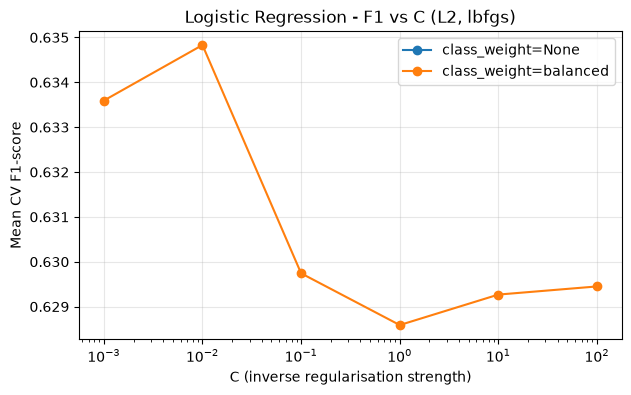

In [37]:
lbfgs_res = cv_results[(cv_results['param_model__solver'] == 'lbfgs')]
plt.figure(figsize=(7, 4))
for cw in [None, 'balanced']:
    subset = lbfgs_res[lbfgs_res['param_model__class_weight'].astype(str) == str(cw)]
    plt.plot(subset['param_model__C'].astype(float), subset['mean_test_f1'], marker='o', label=f'class_weight={cw}')
plt.xscale('log')
plt.xlabel('C (inverse regularisation strength)')
plt.ylabel('Mean CV F1-score')
plt.title('Logistic Regression - F1 vs C (L2, lbfgs)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [38]:
best_lr = grid_lr.best_estimator_
y_pred  = best_lr.predict(X_test)
y_proba = best_lr.predict_proba(X_test)[:, 1]

def evaluate(y_true, y_pred, y_proba):
    return {
        'Accuracy':  accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred),
        'Recall':    recall_score(y_true, y_pred),
        'F1-score':  f1_score(y_true, y_pred),
        'ROC-AUC':   roc_auc_score(y_true, y_proba),
        'PR-AUC':    average_precision_score(y_true, y_proba)
    }

print('Classification Report - Tuned Logistic Regression')
print(classification_report(y_test, y_pred, target_names=['No Churn', 'Churn'], digits=4))

Classification Report - Tuned Logistic Regression
              precision    recall  f1-score   support

    No Churn     0.9079    0.7237    0.8054      1035
       Churn     0.5103    0.7968    0.6221       374

    accuracy                         0.7431      1409
   macro avg     0.7091    0.7602    0.7138      1409
weighted avg     0.8023    0.7431    0.7567      1409



In [39]:
baseline_lr.fit(X_train, y_train)
base_pred  = baseline_lr.predict(X_test)
base_proba = baseline_lr.predict_proba(X_test)[:, 1]

lr_comparison = pd.DataFrame({
    'Baseline LR': evaluate(y_test, base_pred, base_proba),
    'Tuned LR':    evaluate(y_test, y_pred, y_proba)
}).T
display(lr_comparison.round(4))

,Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC
Baseline LR,0.8055,0.6678,0.5321,0.5923,0.8472,0.6646
Tuned LR,0.7431,0.5103,0.7968,0.6221,0.8464,0.6602


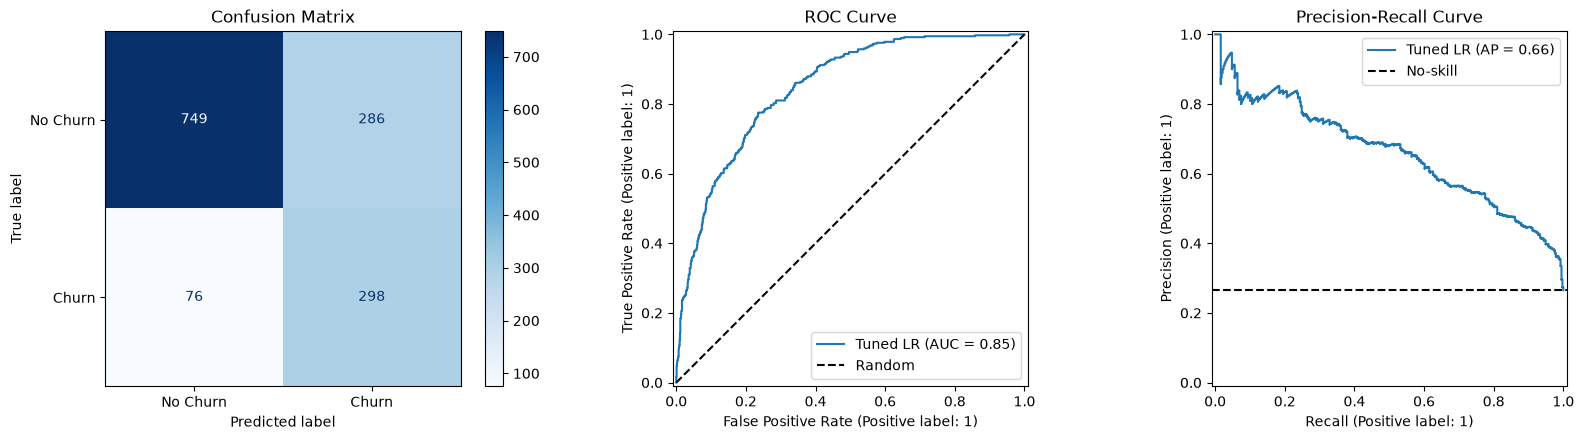

In [40]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=['No Churn', 'Churn'],
                                        cmap='Blues', ax=axes[0])
axes[0].set_title('Confusion Matrix')

RocCurveDisplay.from_predictions(y_test, y_proba, name='Tuned LR', ax=axes[1])
axes[1].plot([0, 1], [0, 1], 'k--', label='Random')
axes[1].set_title('ROC Curve')
axes[1].legend()

PrecisionRecallDisplay.from_predictions(y_test, y_proba, name='Tuned LR', ax=axes[2])
axes[2].axhline(y_test.mean(), color='k', linestyle='--', label='No-skill')
axes[2].set_title('Precision-Recall Curve')
axes[2].legend()

plt.tight_layout()
plt.show()

,Feature,Coefficient,Odds Ratio
11,Contract,-0.5594,0.5716
13,TotalCharges_log,-0.4946,0.6098
18,InternetService_No,-0.4399,0.6441
17,InternetService_Fiber_optic,0.4295,1.5366
3,tenure,-0.2987,0.7418
20,PaymentMethod_Electronic_check,0.1809,1.1983
12,PaperlessBilling,0.1695,1.1847
10,StreamingMovies,0.1642,1.1785
9,StreamingTV,0.1554,1.1682
4,MultipleLines,0.1301,1.1390


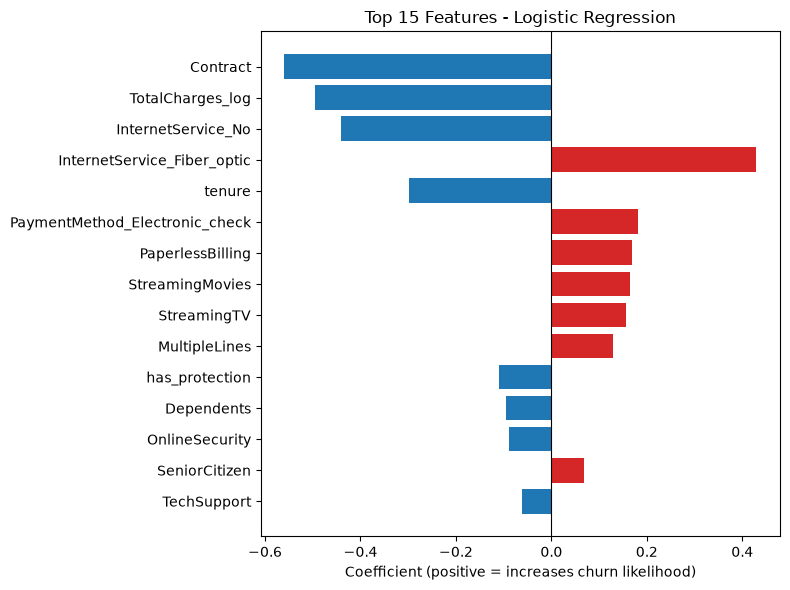

In [41]:
coef = best_lr.named_steps['model'].coef_[0]
coef_df = pd.DataFrame({'Feature': X_train.columns,
                        'Coefficient': coef,
                        'Odds Ratio': np.exp(coef)})
coef_df = coef_df.reindex(coef_df['Coefficient'].abs().sort_values(ascending=False).index)
display(coef_df.head(15).round(4))

top15 = coef_df.head(15).iloc[::-1]
plt.figure(figsize=(8, 6))
plt.barh(top15['Feature'], top15['Coefficient'],
         color=['tab:red' if c > 0 else 'tab:blue' for c in top15['Coefficient']])
plt.axvline(0, color='k', linewidth=0.8)
plt.xlabel('Coefficient (positive = increases churn likelihood)')
plt.title('Top 15 Features - Logistic Regression')
plt.tight_layout()
plt.show()

In [42]:
joblib.dump(best_lr, 'logistic_regression_model.pkl')
lr_comparison.to_csv('lr_results.csv')
print('Model and results saved.')

Model and results saved.
